# Diebold–Mariano tests and the source of the drift

CRPS comparisons on the validation fold, with daily-averaged loss differences and Newey–West variances. The drift figures also show the train period.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windai.data.build import load_dataset
from windai.data.splits import training_rows, evaluation_rows, history_rows
from windai.data.first_stage import load_nowcast_wind, park_cf
from windai.data.parks import parks_table, capacity_matrix
from windai.models.EMOS import EMOS, SeasonalEMOS, RollingEMOS, ALL_MEMBERS
from windai.models.baselines import RawEnsemble
from windai.evaluation.evaluate import score_rows
from windai.evaluation import dependence as dep

pd.set_option("display.width", 200)
df, curve = load_dataset("train", fit="val")
train, history, val = training_rows(df, "val"), history_rows(df, "val"), evaluation_rows(df, "val")
hidden = val.drop(columns=["power", "cf"])
y = val["power"].to_numpy()

models = {"raw_ensemble": (RawEnsemble(), train), "emos_static": (EMOS(), train),
          "emos_seasonal": (SeasonalEMOS(), train), "emos_rolling_90": (RollingEMOS(90), history),
          "emos_rolling_365": (RollingEMOS(365), history)}
loss = {}
for name, (model, data) in models.items():
    r = score_rows(model.fit(data).predict(hidden), y)
    loss[name] = r["crps_exact"] if "crps_exact" in r else r["crps_sample"]
keys = r[["zone", "issue_time"]]
pd.DataFrame(loss).groupby(keys["zone"].to_numpy()).mean().round(2)

,raw_ensemble,emos_static,emos_seasonal,emos_rolling_90,emos_rolling_365
ELSPOT NO1,38.01,30.68,30.55,31.47,32.14
ELSPOT NO2,104.83,94.95,91.85,91.97,92.46
ELSPOT NO3,134.24,124.93,123.62,123.68,124.60
ELSPOT NO4,77.77,66.33,65.42,59.90,60.53


## Diebold–Mariano tests

In [2]:
PAIRS = [("emos_static", "raw_ensemble"), ("emos_rolling_90", "emos_static"), ("emos_seasonal", "emos_static"),
         ("emos_rolling_90", "emos_seasonal"), ("emos_rolling_90", "emos_rolling_365")]
dates = keys["issue_time"].dt.tz_convert(None).dt.normalize()

def dm_table(mask, lag=7):
    out = {}
    for a, b in PAIRS:
        res = dep.diebold_mariano(loss[a][mask], loss[b][mask], dates[mask], lag=lag)
        out[f"{a} vs {b}"] = res
    return pd.DataFrame(out).T

all_rows = np.ones(len(keys), dtype=bool)
overall = pd.concat({f"lag {L}": dm_table(all_rows, L)[["rel_diff", "stat", "p"]] for L in (3, 7, 14)}, axis=1)
overall.round(4)

lag 3                     lag 7                    lag 14                 
                                    rel_diff     stat       p rel_diff     stat       p rel_diff     stat       p
emos_static vs raw_ensemble          -0.1070 -18.9968  0.0000  -0.1070 -17.1473  0.0000  -0.1070 -15.5672  0.0000
emos_rolling_90 vs emos_static       -0.0311  -3.2744  0.0011  -0.0311  -3.0891  0.0020  -0.0311  -3.1168  0.0018
emos_seasonal vs emos_static         -0.0172  -2.1630  0.0305  -0.0172  -2.0356  0.0418  -0.0172  -1.8281  0.0675
emos_rolling_90 vs emos_seasonal     -0.0141  -1.2637  0.2063  -0.0141  -1.1748  0.2401  -0.0141  -1.2189  0.2229
emos_rolling_90 vs emos_rolling_365  -0.0087  -1.0600  0.2891  -0.0087  -0.9898  0.3223  -0.0087  -0.9175  0.3589

In [3]:
# Per zone, lag 7: relative CRPS difference (negative favours the first model), p-value, and the p-value adjusted
# with Benjamini-Hochberg over the 20 per-zone tests
per_zone = {zone: dm_table((keys["zone"] == zone).to_numpy()) for zone in sorted(keys["zone"].unique())}
pz = pd.concat({z: t[["rel_diff", "p"]] for z, t in per_zone.items()}, axis=1)
p_cols = [c for c in pz.columns if c[1] == "p"]
adj = dep.benjamini_hochberg(pz[p_cols].to_numpy().ravel()).reshape(pz[p_cols].shape)
for (z, _), col in zip(p_cols, adj.T):
    pz[(z, "p_BH")] = col
pz.sort_index(axis=1, level=0, sort_remaining=False).round(4)

ELSPOT NO1                 ELSPOT NO2                 ELSPOT NO3                 ELSPOT NO4                
                                      rel_diff       p    p_BH   rel_diff       p    p_BH   rel_diff       p    p_BH   rel_diff       p    p_BH
emos_static vs raw_ensemble            -0.1929  0.0000  0.0000    -0.0942  0.0000  0.0000    -0.0694  0.0000  0.0000    -0.1470  0.0000  0.0000
emos_rolling_90 vs emos_static          0.0258  0.2396  0.5325    -0.0314  0.0135  0.0384    -0.0100  0.4497  0.7097    -0.0969  0.0047  0.0190
emos_seasonal vs emos_static           -0.0043  0.8312  0.9235    -0.0327  0.0086  0.0285    -0.0105  0.5150  0.7097    -0.0138  0.5304  0.7097
emos_rolling_90 vs emos_seasonal        0.0302  0.3399  0.6797     0.0013  0.9244  0.9730     0.0005  0.9758  0.9758    -0.0843  0.0217  0.0543
emos_rolling_90 vs emos_rolling_365    -0.0209  0.4435  0.7097    -0.0053  0.5322  0.7097    -0.0073  0.5737  0.7171    -0.0103  0.6314  0.7429

### Per zone and UTC target hour

One test per zone and hour, with p-values adjusted by Benjamini–Hochberg within each pair of models.

In [4]:
target_hour = r["target_time"].dt.hour.to_numpy()          # UTC; the rows are in the same order for every model
hourly = []
for a, b in PAIRS:
    recs = []
    for zone in sorted(keys["zone"].unique()):
        for h in range(24):
            m = ((keys["zone"] == zone).to_numpy()) & (target_hour == h)
            res = dep.diebold_mariano(loss[a][m], loss[b][m], dates[m], lag=7)
            recs.append({"pair": f"{a} vs {b}", "zone": zone, "hour": h, **res})
    t = pd.DataFrame(recs)
    t["p_BH"] = dep.benjamini_hochberg(t["p"].to_numpy())
    hourly.append(t)
hourly = pd.concat(hourly, ignore_index=True)
sig = hourly["p_BH"] < 0.05
summary_h = hourly.assign(better=sig & (hourly["mean_diff"] < 0), worse=sig & (hourly["mean_diff"] > 0)) \
    .groupby(["pair", "zone"]).agg(hours_first_better=("better", "sum"), hours_first_worse=("worse", "sum"),
                                   median_rel_diff=("rel_diff", "median"))
summary_h.round(4)

hours_first_better  hours_first_worse  median_rel_diff
pair                                zone                                                              
emos_rolling_90 vs emos_rolling_365 ELSPOT NO1                   0                  0          -0.0220
                                    ELSPOT NO2                   0                  0          -0.0053
                                    ELSPOT NO3                   0                  0          -0.0060
                                    ELSPOT NO4                   0                  0          -0.0088
emos_rolling_90 vs emos_seasonal    ELSPOT NO1                   0                  0           0.0254
                                    ELSPOT NO2                   0                  0           0.0057
                                    ELSPOT NO3                   0                  0          -0.0052
                                    ELSPOT NO4                   0                  0          -0.0774
emos_rolling_90 vs emos_static      ELSPOT NO1                   0                  0           0.0406
                                    ELSPOT NO2                   1                  0          -0.0320
                                    ELSPOT NO3                   0                  0          -0.0055
                                    ELSPOT NO4                   5                  0          -0.0921
emos_seasonal vs emos_static        ELSPOT NO1                   0                  0          -0.0069
                                    ELSPOT NO2                   0                  0          -0.0345
                                    ELSPOT NO3                   0                  0          -0.0037
                                    ELSPOT NO4                   0                  0          -0.0141
emos_static vs raw_ensemble         ELSPOT NO1                  24                  0          -0.1547
                                    ELSPOT NO2                  24                  0          -0.0929
                                    ELSPOT NO3                  19                  0          -0.0469
                                    ELSPOT NO4                  24                  0          -0.1457

EMOS beats the raw ensemble clearly (−10.7 % CRPS), in every zone and in 91 of the 96 zone-hours after correction. The 90-day window beats static EMOS overall (−3.1 %, p ≈ 0.002), significantly in NO2 and NO4 after correction. Seasonal EMOS against static is borderline overall (−1.7 %, p 0.03–0.07 depending on the lag) and significant only in NO2. The 90-day window against seasonal EMOS is significant only in NO4 (−8.4 %, p = 0.02, 0.054 after correction), the zone with drift. The 90- and 365-day windows can't be told apart. Per hour, the tests have little power: apart from EMOS against the raw ensemble, only a handful of hours in NO4 (and one in NO2) remain significant after correction.

## Where does the drift come from?

The bias of the raw power ensemble split into a mapping part (observed CF minus the power curve on Nowcast wind) and a weather part (the curve on Nowcast wind minus the members' mean).

In [5]:
wind = load_nowcast_wind()
parks = parks_table()
d = df.loc[df["fold"].isin(["train", "val"]) & df["cf"].notna()].reset_index(drop=True)
d["cf_now"], d["ws_now"] = np.nan, np.nan
for zone in d["zone"].unique():
    rows = np.flatnonzero((d["zone"] == zone).to_numpy())
    covered = parks.loc[(parks["zone"] == zone) & parks["has_weather"] & parks["park"].isin(wind.columns)]
    W = wind[covered["park"].tolist()].to_numpy(dtype=float)
    idx = wind.index.get_indexer(d["target_time"].iloc[rows])
    ok = (idx >= 1) & (idx < len(wind) - 1)
    rows, idx = rows[ok], idx[ok]
    capw = capacity_matrix(covered, d["issue_time"].iloc[rows])
    pc = park_cf(curve.params[zone], W[idx - 1], W[idx], W[idx + 1])
    complete = np.isfinite(pc).all(axis=1)
    total = capw.sum(axis=1)
    d.loc[rows[complete], "cf_now"] = ((capw * pc).sum(axis=1) / total)[complete]
    d.loc[rows[complete], "ws_now"] = ((capw * W[idx]).sum(axis=1) / total)[complete]
del wind
d = d.dropna(subset=["cf_now"])
d["p_mean"] = d[ALL_MEMBERS].mean(axis=1)
d["ws_mean"] = d[[f"ws_{m:02d}" for m in range(15)]].mean(axis=1)
d["total"] = d["cf"] - d["p_mean"]
d["mapping"] = d["cf"] - d["cf_now"]                # power curve and parks, with perfect wind
d["weather"] = d["cf_now"] - d["p_mean"]            # weather forecast, through the same curve
d["wind_bias"] = d["ws_mean"] - d["ws_now"]         # MEPS ensemble mean minus Nowcast, m/s
d["month"] = pd.to_datetime(d["target_time"]).dt.tz_convert(None).dt.to_period("M").dt.to_timestamp()
print(len(d), "rows with Nowcast;", d.groupby("fold").size().to_dict())

139218 rows with Nowcast; {'train': 105138, 'val': 34080}


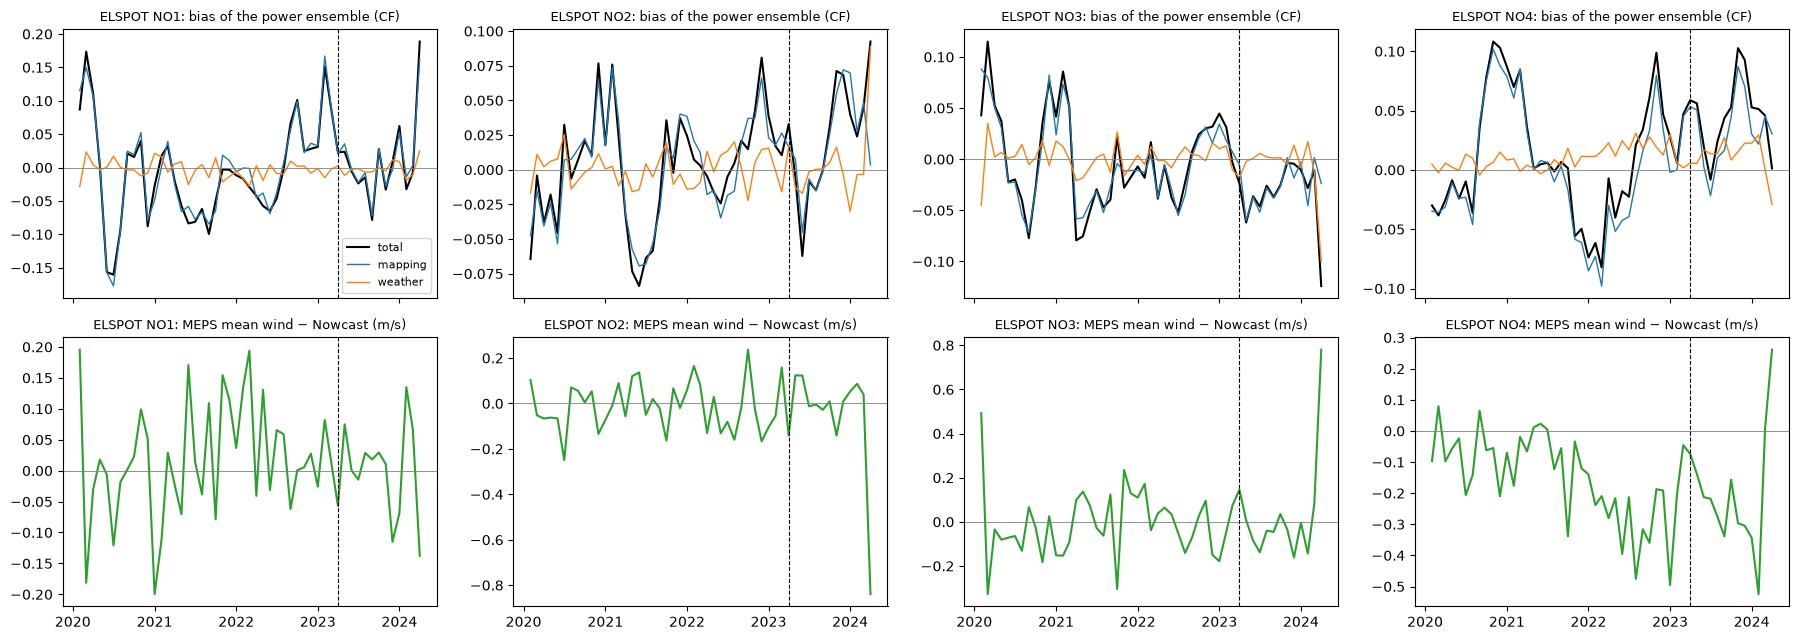

In [6]:
mon = d.groupby(["zone", "month"])[["total", "mapping", "weather", "wind_bias"]].mean().reset_index()
zones = sorted(d["zone"].unique())
fig, axes = plt.subplots(2, 4, figsize=(18, 6.5), sharex=True)
for j, zone in enumerate(zones):
    g = mon.loc[mon["zone"] == zone]
    ax = axes[0, j]
    for col, c in [("total", "k"), ("mapping", "C0"), ("weather", "C1")]:
        ax.plot(g["month"], g[col], color=c, lw=1.5 if col == "total" else 1, label=col)
    ax.axhline(0, color="0.5", lw=0.6); ax.axvline(pd.Timestamp("2023-04-01"), color="k", ls="--", lw=0.8)
    ax.set_title(f"{zone}: bias of the power ensemble (CF)", fontsize=9)
    ax = axes[1, j]
    ax.plot(g["month"], g["wind_bias"], color="C2")
    ax.axhline(0, color="0.5", lw=0.6); ax.axvline(pd.Timestamp("2023-04-01"), color="k", ls="--", lw=0.8)
    ax.set_title(f"{zone}: MEPS mean wind − Nowcast (m/s)", fontsize=9)
axes[0, 0].legend(fontsize=8)
import matplotlib.dates as mdates
for ax in axes.flat:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

In [7]:
# Yearly means per zone (April to March, matching the folds): how much of the shift between years is mapping
# and how much is weather
d["year"] = (pd.to_datetime(d["issue_date"]) - pd.DateOffset(months=3)).dt.year.astype(str) + "/" + \
            ((pd.to_datetime(d["issue_date"]) - pd.DateOffset(months=3)).dt.year + 1).astype(str).str[-2:]
d.groupby(["zone", "year"])[["total", "mapping", "weather", "wind_bias"]].mean().unstack("zone").round(3)

total                                     mapping                                     weather                                   wind_bias                                 
zone    ELSPOT NO1 ELSPOT NO2 ELSPOT NO3 ELSPOT NO4 ELSPOT NO1 ELSPOT NO2 ELSPOT NO3 ELSPOT NO4 ELSPOT NO1 ELSPOT NO2 ELSPOT NO3 ELSPOT NO4 ELSPOT NO1 ELSPOT NO2 ELSPOT NO3 ELSPOT NO4
year                                                                                                                                                                                   
2019/20      0.149     -0.022      0.097     -0.040      0.142     -0.027      0.082     -0.036      0.008      0.005      0.014     -0.004     -0.069     -0.044     -0.111      0.077
2020/21     -0.025      0.013      0.014      0.040     -0.027      0.012      0.010      0.034      0.001      0.001      0.005      0.006     -0.020     -0.026     -0.068     -0.098
2021/22     -0.043     -0.019     -0.029     -0.023     -0.036     -0.015     -0.026     -0.030     -0.008     -0.004     -0.003      0.007      0.056      0.025      0.052     -0.104
2022/23      0.022      0.015      0.000      0.022      0.026      0.011     -0.003      0.004     -0.004      0.005      0.003      0.019      0.019     -0.037     -0.026     -0.282
2023/24     -0.002      0.020     -0.026      0.049      0.001      0.022     -0.026      0.034     -0.003     -0.002     -0.001      0.015      0.007      0.004     -0.028     -0.237

The bias is almost entirely in the mapping, in every zone: a seasonal cycle plus level shifts between years. The weather part stays within about ±0.02 CF. The exception is NO4, where the MEPS mean wind falls 0.2–0.3 m/s below Nowcast from 2022 on, which adds a small under-forecast, about half the size of its mapping bias. (The last month covers two days only.) The drift therefore sits between wind and power, in the power curve and the parks, rather than in the weather forecast.